# Experiência final: duplicação, validação e recombinação

Pergunta: **How does cross-label duplication affect the evaluation and prediction of medical specialties from clinical text?** Comparamos NB, LR e SVC. LR/SVC usam originais, misturas de secções ou cópias das mesmas fontes; todas as configurações são avaliadas com e sem exclusão de classes observadas. Cinco folds por linhas e cinco por notas representam cenários separados.

A regra de promoção foi congelada antes destes ajustes, após exploração anterior. O teste oficial só gera `results.txt` depois da seleção e do ajuste; os seus scores são desconhecidos.


In [1]:
from pathlib import Path
import json
import subprocess
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [path / "help-the-doctors" for path in candidates.copy()]
ROOT = next(path for path in candidates if (path / "run_final_evaluation.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from config import FINAL_EVALUATION_DIR
from classify import record_selection, main as generate_results
import build_paper_assets
print(ROOT)

D:\projetos\faculdade\LN\help-the-doctors


## Desenho e hipótese

LR e SVC usam TF-IDF separado de `sample_name`/`transcription`, palavras/bigramas, frequência sublinear, `min_df=2`, `C=0.25`. NB usa a descrição e Porter. A exclusão usa título e transcrição normalizados, também em NB; o índice contém apenas originais do treino do fold. Inputs totalmente vazios não coincidem. Sem correspondência ou com todas as classes excluídas, conserva-se a previsão original.

A recombinação troca uma secção entre originais da mesma especialidade, do mesmo treino e de outro grupo de duplicados. O controlo repete as mesmas fontes, no mesmo número e com os mesmos pesos. Cinco variantes são inspecionadas antes dos ajustes; podem combinar factos incompatíveis e não são casos clínicos validados. O plano e os hashes ficam em `augmentation_decision_plan.json`.

Uma mistura só é promovida se melhorar macro F1 e F1 de Dermatology, perder no máximo um ponto de accuracy e cumprir os mínimos oficiais, face ao original da mesma família e ao SVC atual, no cenário por linhas com exclusão. Caso contrário, mantém-se o SVC. Cópias e scores agrupados são diagnósticos. Ambos os protocolos são desenvolvimento exploratório, sem confirmação independente.


In [2]:
REPEAT_EXPERIMENT = False
if REPEAT_EXPERIMENT or not (FINAL_EVALUATION_DIR / "experiment.json").exists():
    subprocess.run([sys.executable, str(ROOT / "run_final_evaluation.py")], cwd=ROOT, check=True)

selection = record_selection()  # Requires completed runs, unchanged sources/artifacts.
summary = pd.read_csv(FINAL_EVALUATION_DIR / "summary.csv", sep=";")
display(summary[["protocol", "candidate_id", "accuracy", "f1_macro", "min_f1"]])
print("Selected:", selection["candidate_id"], selection["decoder"])
print(selection["evaluation_status"])

,protocol,candidate_id,accuracy,f1_macro,min_f1
0,stratified_rows_development,NB,0.386662,0.132274,0.000000
1,stratified_rows_development,NB+EXCL,0.554140,0.353492,0.000000
2,stratified_rows_development,B,0.487823,0.518108,0.318584
3,stratified_rows_development,B+EXCL,0.766205,0.732672,0.477612
4,stratified_rows_development,D,0.482952,0.516137,0.339130
5,stratified_rows_development,D+EXCL,0.736605,0.701314,0.400000
6,stratified_rows_development,E,0.480704,0.513865,0.342105
7,stratified_rows_development,E+EXCL,0.732484,0.698110,0.394366
8,stratified_rows_development,SVC,0.461596,0.497745,0.238202
9,stratified_rows_development,SVC+EXCL,0.775571,0.752645,0.481481


Selected: SVC_AUG+EXCL exclude_seen
Exploratory development selection after corpus/annotation inspection and external methodological review; neither row nor grouped CV is an independent post-selection test evaluation. Exclusion assumes that an identical input's next annotation tends to use a previously unseen label.


## Resultados por classe e erros fora do treino

Os protocolos respondem a cenários diferentes. As métricas e erros identificam candidato e protocolo; não são scores oficiais. A comparação entre recombinação e cópias controla a repetição de fontes em LR/SVC. As auditorias anteriores são exploração histórica.


In [3]:
design = json.loads((FINAL_EVALUATION_DIR / "design.json").read_text(encoding="utf-8"))
print("Sources and implementation hashes are recorded before fitting.")
per_class = pd.read_csv(FINAL_EVALUATION_DIR / "metrics_per_class.csv", sep=";")
display(per_class.loc[per_class.candidate_id.eq(selection["candidate_id"])])
errors_path = FINAL_EVALUATION_DIR / selection["protocol"] / ("errors_" + selection["candidate_id"] + ".csv")
errors = pd.read_csv(errors_path, sep=";")
columns = [name for name in ["record_id", "sample_name", "true_class", "predicted_class", "has_train_match", "changed", "transcription"] if name in errors]
preview = errors[columns].head(3).copy()
if "transcription" in preview:
    preview["transcription"] = preview["transcription"].fillna("").str.slice(0, 180)
display(preview)

Sources and implementation hashes are recorded before fitting.


,protocol,seed,candidate_id,model_id,decoder,class,precision,recall,f1,support
132,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Cardiovascular-Pulmonary,0.755882,0.831715,0.791988,309
133,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Dermatology,0.565217,0.520000,0.541667,25
134,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Gastroenterology,0.722222,0.800000,0.759124,195
135,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,General Medicine,0.697417,0.891509,0.782609,212
136,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Neurology,0.693122,0.711957,0.702413,184
137,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Neurosurgery,0.515385,0.848101,0.641148,79
138,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Obstetrics-Gynecology,0.721212,0.875000,0.790698,136
139,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Ophthalmology,0.769231,0.958904,0.853659,73
140,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Orthopedic,0.737463,0.833333,0.782473,300
141,stratified_rows_development,0,SVC_AUG+EXCL,SVC_AUG,exclude_seen,Psychiatry-Psychology,0.840909,0.902439,0.870588,41


,record_id,sample_name,true_class,predicted_class,has_train_match,changed,transcription
0,41,Hypertension - Consult,Cardiovascular-Pulmonary,General Medicine,False,False,HISTORY OF PRESENT ILLNESS: The patient is an ...
1,54,CyberKnife Treatment - Followup,Cardiovascular-Pulmonary,General Medicine,False,False,HISTORY OF PRESENT ILLNESS: The patient is a 6...
2,118,Cardioversion - Direct Current - 1,Cardiovascular-Pulmonary,Surgery,False,False,"PROCEDURE:Direct-current cardioversion.,BRIEF ..."


## Atualizar tabelas, matriz e PDF

Os artefactos são gerados dos resultados medidos e da seleção verificada. `paper.tex` segue o template de duas colunas, 10 pt e Bera. `powershell -NoProfile -ExecutionPolicy Bypass -File .\build_paper.ps1 -Offline` compila e verifica o máximo de três páginas no PDF completo, incluindo a bibliografia; o registo fica em `output/pdf/compilation.json`. Este limite mais estrito segue a preferência mais recente do utilizador, embora o enunciado/template exclua formalmente a bibliografia.

A identidade está preenchida: grupo **64**, Tiago Pinto, Gonçalo Narciso Rolo, Gabriel Alexandre Lino Simões Ferreira e Miguel Neves Antão Ermida Parreira, com **25% de contribuição cada**. Após compilar, `python prepare_submission.py --group 64` gera `output/submission/64.pdf` e `64.zip`. A reprodução das previsões permanece inalterada; preencher a identidade e recompilar não exige repetir a avaliação ou a inferência.


{
  "status": "ready",
  "selected_candidate_id": "SVC_AUG+EXCL",
  "selected_model_id": "SVC_AUG",
  "metrics": {
    "accuracy": 0.7740726863994005,
    "f1_macro": 0.7545189858436855,
    "min_f1": 0.5416666666666666,
    "f1_dermatology": 0.5416666666666666
  },
  "output_dir": "D:\\projetos\\faculdade\\LN\\help-the-doctors\\paper_assets",
  "error_candidates": "D:\\projetos\\faculdade\\LN\\help-the-doctors\\paper_assets\\error_candidates.csv"
}


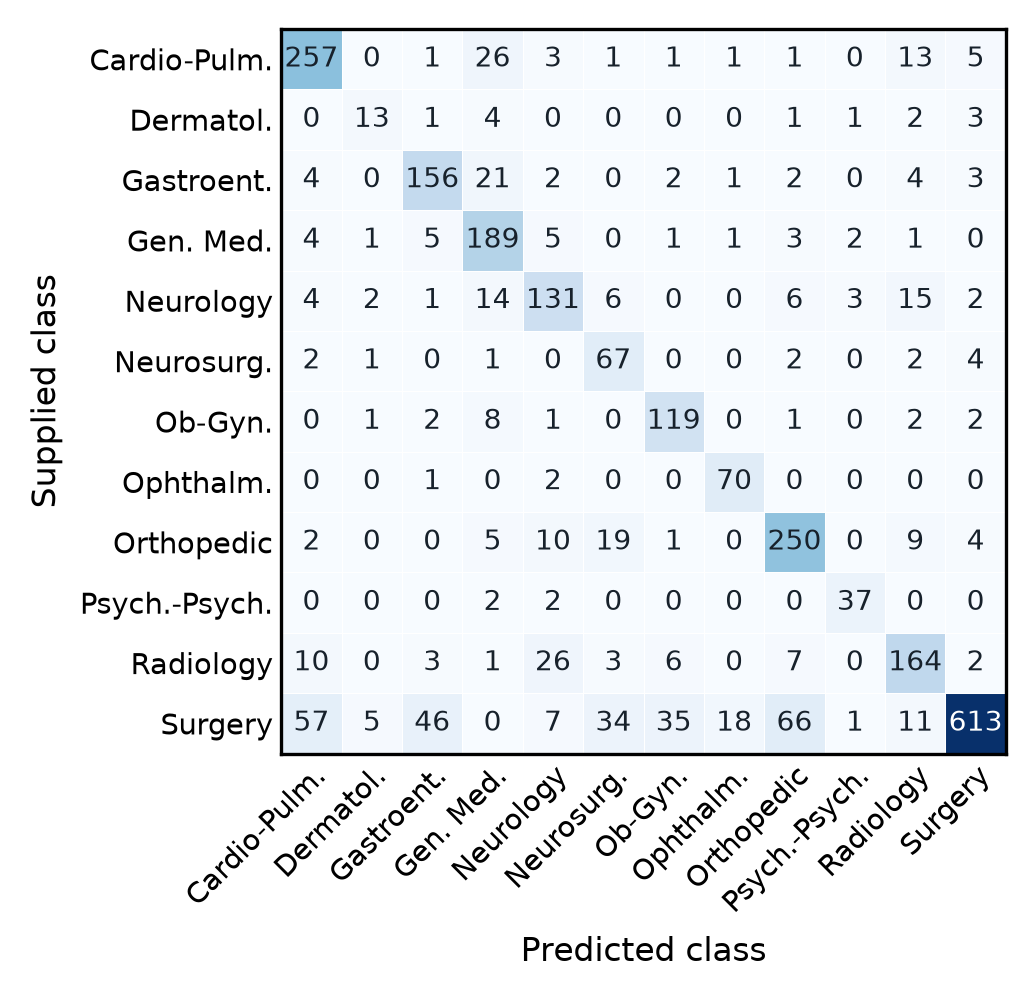

In [4]:
assets = build_paper_assets.main([])
display(Image(filename=str(ROOT / "paper_assets" / "confusion_matrix.png")))

## Ajustar em todo o treino e gerar o teste limpo

O ajuste usa todos os originais e o mesmo helper da configuração avaliada. O índice de exclusão é construído dos originais, nunca de descendentes sintéticos. O teste não determina grupos, modelos, parâmetros, fontes de augmentation ou a regra. A linha N de `results.txt` corresponde ao registo CSV N do teste, sem cabeçalho.

In [5]:
generate_results([])
inference = json.loads((ROOT / "outputs" / "final" / "inference.json").read_text(encoding="utf-8"))
assert inference["original_training_cases"] == 2669
assert inference["exclusion_index_original_training_rows"] == 2669
assert inference["test_cases"] == inference["results_lines"] == 398
assert inference["selected_model"]["candidate_id"] == selection["candidate_id"]
assert inference["test_metrics"] is None
print("Verified", inference["results_lines"], "ordered predictions; official test scores are unknown.")

Selected SVC_AUG+EXCL: LinearSVC / exclude_seen
Fit on all 2669 original cases; wrote 398 predictions to D:\projetos\faculdade\LN\help-the-doctors\results.txt.
Row/grouped scores are exploratory development CV. Official test scores are unknown.
Verified 398 ordered predictions; official test scores are unknown.
